# Lab 6: Geodemographic analysis
1. Define the main goal for the geodemographic classification (marketing, retail and service planning).  
2. Look for census data from the selected city for which you would like to generate the geodemographic classification.
3. The census data at the Output Area OA level. Select multiple topics of at least four topics (socio-demographics, economics, health, and so on). Describe your topic selection accordingly based on the goal of your geodemographic classification. For example, if your geodemographics are related to marketing, Economic variables might be the appropriate selection. 
4. Identify the variables that will be crucial for effectively segmenting neighbourhoods. Evaluate how this choice may impact the classification results, including **a DEA analysis**.
5. Prepare, adjust or clean the dataset **addressing any missing values or outliers** that could distort the clustering results.
6. Include **standardisation between areas and variables**. Make an appropriate analysis and adjust the variable selection accordingly for any multicollinearity.
7. Utilize the **k-means** clustering algorithm to create a classification based on the selected variables.
8. Define the **optimum number of clusters** (i.e., using the Elblow method). Experiment with different values of k.
9. **Evaluate your cluster groups (e.g., using PCA)** and interpret your cluster centres. Describe your results and repeat the process to adjust the variable selection and cluster groups to provide more meaningful results for your geodemographic goal. Interpret the characteristics of each cluster. **What demographic patterns or similarities are prevalent within each group?**
10. **Map the final cluster groups**
11. Finish the analysis by **naming the final clusters and plotting a final map that includes the census values and the provided names**.
12. Finally, acknowledge the subjective nature of classification and make analytical decisions to produce an optimum classification for your specific purpose. Reflect on the challenges and insights gained during the classification process. Ensure you document your analytical decisions and the rationale behind any important decision. Once your geodemographics are constructed, **describe the potential use cases for the geodemographic classification you have built** based on your initial goal.

In [1]:
# importing necessary libraries
# !pip install geopandas scikit-learn matplotlib scipy

import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

pd.set_option("display.precision", 2)
RANDOM_SEED = 42   # keeps results reproducible for everyone in the class

## Goal of classification

My goal with this classification is to determine the ethnic and economic backgrounds of residents in the city for use in marketing of cultural events. I have chosen Aberdeen becaause I have never analysed it before and I am curious about the city's demographic breakdown. 

## Topic Selection

I chose the following topics because I think the would be the most useful in understanding how to market cultural events (e.g. theatre, film, food, music) to residents, my justifications are in parentheses:
* KS102SC - Age structure - Demographics (for age-appropriate marketing)
* KS103SC - Marital and civil partnership status - Demographics (to market things towards people in relationships and those who are not)
* KS105SC - Household composition - Households (to appeal to diverse sets of generations and promote family activities)
* KS209SCb - Religion - Demographics (religious events, cultural exchange)
* KS601SC - Economic activity - Economic (what people might be able to afford or be willing to spend on things marketed to them)
* KS605SC - Industry - Economic (marketing for events related to industries that people work in)
* QS104SC - Sex - Demographics (could relate to differences among activities and events attended)
* QS302SC - General Health - Health (to determine how to make things accessible, proper health and safety measures)
* QS501SC - Highest level of qualification - Education (educational level could influence the events people might attend)

In [2]:
# merging the census data from Aberdeen into one csv file
import pandas as pd
import os

csv_directory = "lab6_data/aberdeen"

# We need a list of all CSV files in the folder
csv_files = [file for file in os.listdir(csv_directory) if file.endswith(".csv")]

# An empty DataFrame to store the merged data
merged_data = pd.DataFrame()

# Loop through each CSV file
for csv_file in csv_files:
    csv_path = os.path.join(csv_directory, csv_file) # We create a consistent path
    df_csv = pd.read_csv(csv_path, low_memory=False) #read each file
    # Concatenate/Merge all columns, there is a pitfall here, you will get a duplicate oa_code from all csv files.
    merged_data = pd.concat([merged_data, df_csv], axis=1)

# Save the merged dataset. You might want to do some pre-processing.
merged_data.to_csv("lab6_data/aberdeen/merged_census_data.csv", index=False)

In [3]:
merged_data.shape

(46351, 560)

In [4]:
# merging the 
import pandas as pd
import geopandas as gpd

shp_path = "lab6_data/aberdeen/OutputArea2011_MHW.shp"
gdf = gpd.read_file(shp_path)
gdf

,OBJECTID,code,HHcount,Popcount,council,sqkm,hect,masterpc,easting,northing,SHAPE_1_Le,SHAPE_1_Ar,DataZone,geometry
0,1,S00089001,55,115,S12000033,0.03,2.92,AB11 7XY,393374,805012,929.79,2.92e+04,S01006594,"POLYGON ((393393.000 805102.000, 393384.000 80..."
1,2,S00090016,50,100,S12000033,0.02,1.71,AB16 7SX,389779,808556,745.62,1.71e+04,S01006720,"POLYGON ((389796.000 808485.001, 389817.000 80..."
2,3,S00089741,45,109,S12000033,0.05,4.53,AB15 4AH,391312,805970,1156.17,4.53e+04,S01006572,"POLYGON ((391410.771 806073.119, 391383.319 80..."
3,4,S00088978,33,60,S12000033,0.03,3.35,AB10 1SB,393473,806017,1173.63,3.35e+04,S01006585,"POLYGON ((393596.593 806042.095, 393651.000 80..."
4,5,S00090442,64,97,S12000033,0.01,1.29,AB24 1TA,394564,808271,615.20,1.29e+04,S01006667,"POLYGON ((394659.000 808248.000, 394611.964 80..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
46346,46366,S00094726,55,113,S12000035,8.81,881.30,PA75 6QJ,142980,752084,20537.56,8.74e+06,S01007285,"MULTIPOLYGON (((140992.500 757140.000, 140998...."
46347,46367,S00102583,53,132,S12000011,0.02,2.19,G78 1LP,249247,658288,1085.15,2.27e+04,S01008322,"MULTIPOLYGON (((249205.272 658381.836, 249215...."
46348,46368,S00119179,75,192,S12000017,168.93,16893.06,IV40 8JX,184029,816699,87255.32,1.69e+08,S01010669,"MULTIPOLYGON (((186460.000 806314.000, 186460...."
46349,46369,S00119262,63,162,S12000017,12.39,1239.45,KW1 4YB,332641,972819,20008.58,1.24e+07,S01010790,"POLYGON ((331504.549 973428.233, 332026.118 97..."


In [5]:
# creating a gdf of just Aberdeen City output areas
abdn = gdf[gdf["council"] == "S12000033"]
abdn

,OBJECTID,code,HHcount,Popcount,council,sqkm,hect,masterpc,easting,northing,SHAPE_1_Le,SHAPE_1_Ar,DataZone,geometry
0,1,S00089001,55,115,S12000033,2.92e-02,2.92,AB11 7XY,393374,805012,929.79,29183.98,S01006594,"POLYGON ((393393.000 805102.000, 393384.000 80..."
1,2,S00090016,50,100,S12000033,1.71e-02,1.71,AB16 7SX,389779,808556,745.62,17122.25,S01006720,"POLYGON ((389796.000 808485.001, 389817.000 80..."
2,3,S00089741,45,109,S12000033,4.53e-02,4.53,AB15 4AH,391312,805970,1156.17,45335.82,S01006572,"POLYGON ((391410.771 806073.119, 391383.319 80..."
3,4,S00088978,33,60,S12000033,3.35e-02,3.35,AB10 1SB,393473,806017,1173.63,33488.24,S01006585,"POLYGON ((393596.593 806042.095, 393651.000 80..."
4,5,S00090442,64,97,S12000033,1.29e-02,1.29,AB24 1TA,394564,808271,615.20,12945.38,S01006667,"POLYGON ((394659.000 808248.000, 394611.964 80..."
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5581,5586,S00089080,42,100,S12000033,6.84e-03,0.68,AB11 8HN,395125,804735,471.38,6839.85,S01006632,"POLYGON ((395144.060 804751.926, 395156.000 80..."
5582,5587,S00090629,72,111,S12000033,2.71e-02,2.71,AB10 6DD,393141,805132,1028.82,27146.99,S01006597,"POLYGON ((393224.999 805382.000, 393224.204 80..."
5583,5588,S00089883,46,91,S12000033,2.41e-02,2.41,AB16 5DU,392248,807351,1013.28,24078.53,S01006563,"POLYGON ((392431.000 807330.000, 392374.000 80..."
5584,5589,S00090280,43,91,S12000033,1.31e-02,1.31,AB21 7LS,388930,813130,489.74,13057.13,S01006752,"POLYGON ((389034.979 813077.326, 389016.087 81..."


In [6]:
# merging the csv and abdn data
csv_path = "lab6_data/aberdeen/merged_census_data.csv"
csv_data = pd.read_csv(csv_path, low_memory=False)

# Merge the GeoDataFrame with the DataFrame based on the oa_code
merged_data = abdn.merge(csv_data, left_on='code', right_on='oa_code', how='left')

# You could save the merged data to a new shapefile, but I will skip this now
# but you could do it, in case you need just to read the data you have merged., and avoid
# the previous cell
# merged_data.to_file('data_lab6/glasgow_census_data.shp', index=False)

## Important variables

The most important variables when classifying data for marketing purposes is probably economic data, followed by age. These two variables could be a source of multicolinearity because as people get older, they usually have more money to spend. Household compostition might be influential as well, due to some households having more disposable income than others (possibly because they don't have kids or dependents). Households without dependents might choose to spend money on different things than households that do have dependents. Finally, religion could provide a cultural or moral influence on the way people spend their money, and it would be useful to appeal to those who might strongly align with a particular value system as a marketing strategy.

In [7]:
list(merged_data.columns)

['OBJECTID',
 'code',
 'HHcount',
 'Popcount',
 'council',
 'sqkm',
 'hect',
 'masterpc',
 'easting',
 'northing',
 'SHAPE_1_Le',
 'SHAPE_1_Ar',
 'DataZone',
 'geometry',
 'oa_code',
 'All people',
 '0 to 4',
 '5 to 7',
 '8 to 9',
 '10 to 14',
 '15',
 '16 to 17',
 '18 to 19',
 '20 to 24',
 '25 to 29',
 '30 to 44',
 '45 to 59',
 '60 to 64',
 '65 to 74',
 '75 to 84',
 '85 to 89',
 '90 and over',
 'Mean age',
 'Median age',
 'oa_code.36',
 'All people aged 16 and over',
 'Single (never married or never registered a same-sex civil partnership)',
 'Married',
 'In a registered same-sex civil partnership',
 'Separated (but still legally married or still legally in a same-sex civil partnership)',
 'Divorced or formerly in a same-sex civil partnership which is now legally dissolved',
 'Widowed or surviving partner from a same-sex civil partnership',
 'oa_code.37',
 'All households',
 'One person household: Aged 65 and over',
 'One person household: Aged under 65',
 'One family only: All aged 65

In [8]:
merged_data.info()

<class 'geopandas.geodataframe.GeoDataFrame'>
RangeIndex: 1992 entries, 0 to 1991
Columns: 574 entries, OBJECTID to All people aged 16 and over: Level 4 and above.4
dtypes: float64(9), geometry(1), int64(513), object(51)
memory usage: 8.7+ MB


In [9]:
merged_data.head()

,OBJECTID,code,HHcount,Popcount,council,sqkm,hect,masterpc,easting,northing,...,Fair health.4,Bad health.4,Very bad health.4,oa_code.44,All people aged 16 and over.9,All people aged 16 and over: No qualifications.4,All people aged 16 and over: Level 1.4,All people aged 16 and over: Level 2.4,All people aged 16 and over: Level 3.4,All people aged 16 and over: Level 4 and above.4
0,1,S00089001,55,115,S12000033,0.03,2.92,AB11 7XY,393374,805012,...,13,1,3,S00089001,103,22,21,12,15,33
1,2,S00090016,50,100,S12000033,0.02,1.71,AB16 7SX,389779,808556,...,12,7,2,S00090016,86,34,29,6,6,11
2,3,S00089741,45,109,S12000033,0.05,4.53,AB15 4AH,391312,805970,...,6,3,1,S00089741,88,6,8,14,3,57
3,4,S00088978,33,60,S12000033,0.03,3.35,AB10 1SB,393473,806017,...,4,0,0,S00088978,55,3,7,19,3,23
4,5,S00090442,64,97,S12000033,0.01,1.29,AB24 1TA,394564,808271,...,20,6,2,S00090442,90,46,14,5,7,18


## Descriptive Statistics Analysis - DEA

I chose data relating to age, economic behaviours, education, relationship status, and household structure because these factors could have the most influence on the purchasing power and preferences of an individual from a marketing perspective. These categories likely all play a role in shaping someone's needs and desires more than most of the other data.

In [10]:
# summary statistics
merged_data['Economically active: Employee: Full-time'].describe()

count    1992.00
mean       39.89
std        16.19
min         0.00
25%        29.00
50%        38.00
75%        49.00
max       124.00
Name: Economically active: Employee: Full-time, dtype: float64

In [11]:
merged_data['30 to 44'].describe()

merged_data['All people aged 16 and over'].describe()

count    1992.00
mean       95.71
std        58.25
min        33.00
25%        72.00
50%        90.00
75%       110.00
max      2069.00
Name: All people aged 16 and over, dtype: float64

In [12]:
merged_data.Married.describe()

count    1992.00
mean       38.77
std        22.86
min         1.00
25%        20.00
50%        35.00
75%        52.25
max       142.00
Name: Married, dtype: float64

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\seaborn\_base.py:948: FutureWarning: When grouping with a length-1 list-like, you will need to pass a length-1 tuple to get_group in a future version of pandas. Pass `(name,)` instead of `name` to silence this warning.
  data_subset = grouped_data.get_group(pd_key)
C:\Users\silog\miniforge3\envs\ua\lib\site-pac

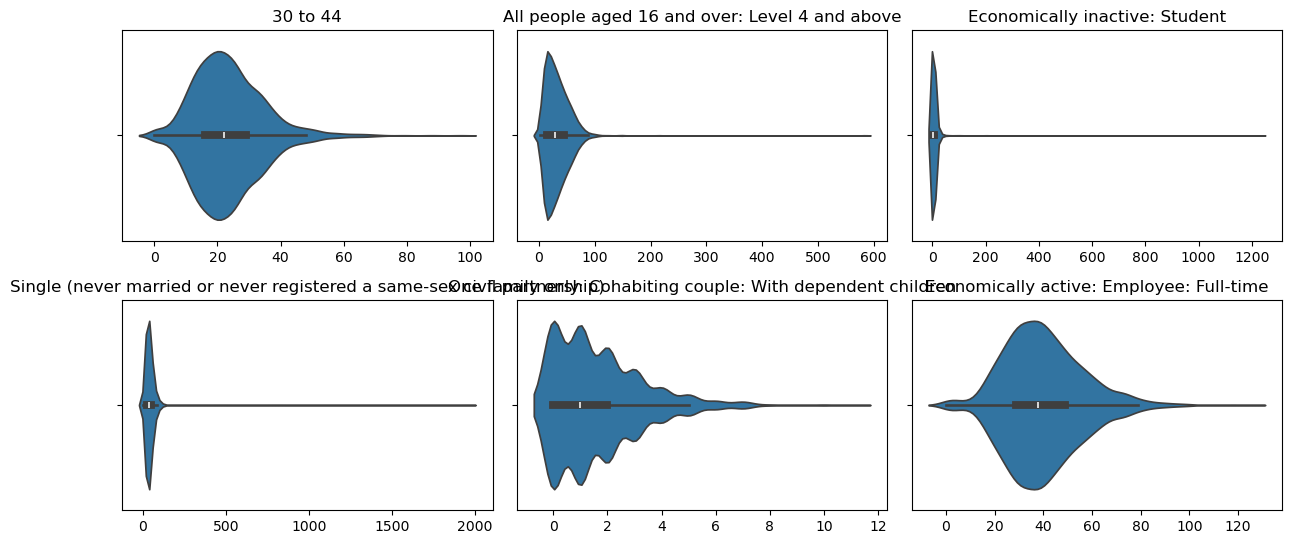

In [13]:
import seaborn as sns
import matplotlib.pyplot as plt

attributes_to_plot = ['30 to 44',
                      'All people aged 16 and over: Level 4 and above',
                      'Economically inactive: Student',                      
                      'Single (never married or never registered a same-sex civil partnership)',                      
                      'One family only: Cohabiting couple: With dependent children',
                      'Economically active: Employee: Full-time']

plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(3, 3, i)
    sns.violinplot(x=merged_data[attribute])
    plt.title(attribute)
    plt.xlabel('')
    plt.ylabel('')

plt.tight_layout()
plt.show()

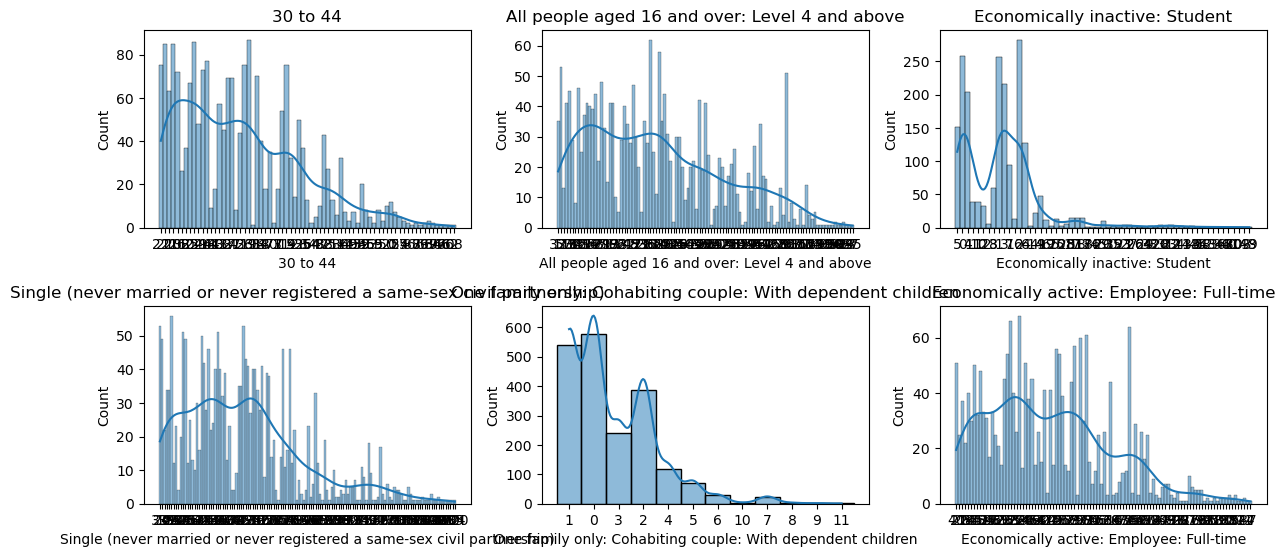

In [14]:
import matplotlib.pyplot as plt

attributes_to_plot = ['30 to 44',
                      'All people aged 16 and over: Level 4 and above',
                      'Economically inactive: Student',                      
                      'Single (never married or never registered a same-sex civil partnership)',                      
                      'One family only: Cohabiting couple: With dependent children',
                      'Economically active: Employee: Full-time']


plt.figure(figsize=(12, 8))

for i, attribute in enumerate(attributes_to_plot, 1):
    plt.subplot(3, 3, i)
    sns.histplot(merged_data[attribute].astype(str), kde=True)
    plt.title(attribute)

plt.tight_layout()
plt.show()

## Subsetting data

In [15]:
def calculate_percentages(dataframe, total_columns, value_columns):

    result_df = pd.DataFrame()

    for total_col, value_col in zip(total_columns, value_columns):
        percentage_col_name = f"{value_col}_percentage"

        if total_col not in dataframe.columns:
            raise ValueError(f"Total column '{total_col}' not found in the DataFrame.")
        # The data have several empty values, so you need to process them, forcing them to be a numeric or NaN value
        dataframe[value_col] = pd.to_numeric(dataframe[value_col], errors='coerce')
        dataframe[total_col] = pd.to_numeric(dataframe[total_col], errors='coerce')
        
        result_df[percentage_col_name] = (dataframe[value_col] / dataframe[total_col]) * 100

    return result_df

# List of the corresponding totals.
total_cols = ['All people aged 16 and over',
              'All people',
              'All people.1','All people.1',
              'All people aged 16 and over.1', 'All people aged 16 and over.1',
              'All households','All households',
              'All people.2','All people.2',
              'All people aged 16 to 74', 'All people aged 16 to 74',
              'All people.3', 'All people.3',
              'All people aged 16 to 74 in employment','All people aged 16 to 74 in employment',
              'All people aged 16 to 74 in employment' ]
# List of the corresponding values. 
value_cols = ['All people aged 16 and over: Level 4 and above',
              '30 to 44',
              'Church of Scotland',
              'No religion',
              'Single (never married or never registered a same-sex civil partnership)',
              'Married',
              'One family only: Married or same-sex civil partnership couple: With dependent children',
              'One person household: Aged under 65',
              'Males',
              'Females',
              'Economically active: Employee: Full-time',
              'Economically inactive: Student',
              'Good health',
              'Bad health',
              'F. Construction', 'J. Information and communication', 'P. Education']

# Later we migth need to rename those columns., for now is ok...
result_dataframe = calculate_percentages(merged_data, total_cols, value_cols)

# Likely you could also do all this in Excel :D
# but what's important is you are aware of the correct total as dominator, census data can be very tricky

In [16]:
result_dataframe.head()

,All people aged 16 and over: Level 4 and above_percentage,30 to 44_percentage,Church of Scotland_percentage,No religion_percentage,Single (never married or never registered a same-sex civil partnership)_percentage,Married_percentage,One family only: Married or same-sex civil partnership couple: With dependent children_percentage,One person household: Aged under 65_percentage,Males_percentage,Females_percentage,Economically active: Employee: Full-time_percentage,Economically inactive: Student_percentage,Good health_percentage,Bad health_percentage,F. Construction_percentage,J. Information and communication_percentage,P. Education_percentage
0,32.04,19.13,33.91,44.35,32.04,52.43,16.36,14.55,47.83,52.17,43.96,5.49,33.91,0.87,6.78,1.69,10.17
1,12.79,21.00,29.00,51.00,23.26,51.16,16.00,20.00,44.00,56.00,53.33,0.00,24.00,7.00,7.27,3.64,7.27
2,64.77,11.01,27.52,30.28,12.50,72.73,28.89,8.89,45.87,54.13,28.38,5.41,23.85,2.75,2.44,2.44,14.63
3,41.82,20.00,5.00,61.67,70.91,21.82,3.03,33.33,58.33,41.67,42.59,20.37,28.33,0.00,5.71,2.86,5.71
4,20.00,20.62,16.49,48.45,54.44,25.56,3.12,43.75,57.73,42.27,22.22,12.35,42.27,6.19,5.88,0.00,5.88


In [17]:
result_dataframe.shape

(1992, 17)

In [18]:
# Concatenate the resulting tables.
concatenated_df = pd.concat([merged_data, result_dataframe], axis=1, ignore_index=False)
concatenated_df.head()

,OBJECTID,code,HHcount,Popcount,council,sqkm,hect,masterpc,easting,northing,...,One person household: Aged under 65_percentage,Males_percentage,Females_percentage,Economically active: Employee: Full-time_percentage,Economically inactive: Student_percentage,Good health_percentage,Bad health_percentage,F. Construction_percentage,J. Information and communication_percentage,P. Education_percentage
0,1,S00089001,55,115,S12000033,0.03,2.92,AB11 7XY,393374,805012,...,14.55,47.83,52.17,43.96,5.49,33.91,0.87,6.78,1.69,10.17
1,2,S00090016,50,100,S12000033,0.02,1.71,AB16 7SX,389779,808556,...,20.00,44.00,56.00,53.33,0.00,24.00,7.00,7.27,3.64,7.27
2,3,S00089741,45,109,S12000033,0.05,4.53,AB15 4AH,391312,805970,...,8.89,45.87,54.13,28.38,5.41,23.85,2.75,2.44,2.44,14.63
3,4,S00088978,33,60,S12000033,0.03,3.35,AB10 1SB,393473,806017,...,33.33,58.33,41.67,42.59,20.37,28.33,0.00,5.71,2.86,5.71
4,5,S00090442,64,97,S12000033,0.01,1.29,AB24 1TA,394564,808271,...,43.75,57.73,42.27,22.22,12.35,42.27,6.19,5.88,0.00,5.88


In [19]:
list(concatenated_df.columns)

['OBJECTID',
 'code',
 'HHcount',
 'Popcount',
 'council',
 'sqkm',
 'hect',
 'masterpc',
 'easting',
 'northing',
 'SHAPE_1_Le',
 'SHAPE_1_Ar',
 'DataZone',
 'geometry',
 'oa_code',
 'All people',
 '0 to 4',
 '5 to 7',
 '8 to 9',
 '10 to 14',
 '15',
 '16 to 17',
 '18 to 19',
 '20 to 24',
 '25 to 29',
 '30 to 44',
 '45 to 59',
 '60 to 64',
 '65 to 74',
 '75 to 84',
 '85 to 89',
 '90 and over',
 'Mean age',
 'Median age',
 'oa_code.36',
 'All people aged 16 and over',
 'Single (never married or never registered a same-sex civil partnership)',
 'Married',
 'In a registered same-sex civil partnership',
 'Separated (but still legally married or still legally in a same-sex civil partnership)',
 'Divorced or formerly in a same-sex civil partnership which is now legally dissolved',
 'Widowed or surviving partner from a same-sex civil partnership',
 'oa_code.37',
 'All households',
 'One person household: Aged 65 and over',
 'One person household: Aged under 65',
 'One family only: All aged 65

In [20]:
# Subsetting the attributes we need, we dont need the total for now.
keep_cols= [
     'code',
     'Popcount',
     'HHcount',
     'DataZone',
     'geometry',
    'All people aged 16 and over: Level 4 and above_percentage',
     '30 to 44_percentage',
     'Church of Scotland_percentage',
     'No religion_percentage',
     'Single (never married or never registered a same-sex civil partnership)_percentage',
     'Married_percentage',
     'One family only: Married or same-sex civil partnership couple: With dependent children_percentage',
     'One person household: Aged under 65_percentage',
     'Males_percentage',
     'Females_percentage',
     'Economically active: Employee: Full-time_percentage',
     'Economically inactive: Student_percentage',
     'Good health_percentage',
     'Bad health_percentage',
     'F. Construction_percentage',
     'J. Information and communication_percentage',
     'P. Education_percentage'
]

aberdeen_census_data = concatenated_df[keep_cols]

In [21]:
# For more easy manipulation we define short column names
short_column_names = {
    'All people aged 16 and over: Level 4 and above_percentage': 'Edu_Level4',
    '30 to 44_percentage': '30to44',
    'Church of Scotland_percentage': 'Ch_of_Scot',
    'No religion_percentage': 'No_Religion',
    'Single (never married or never registered a same-sex civil partnership)_percentage': 'Single',
    'Married_percentage': 'Married',
    'One family only: Married or same-sex civil partnership couple: With dependent children_percentage': 'Family_With_Children',
    'One person household: Aged under 65_percentage': 'Family_1Person',
    'Males_percentage': 'Males',
    'Females_percentage': 'Females',
    'Economically active: Employee: Full-time_percentage': 'Emp_FullTime',
    'Economically active: Unemployed_percentage': 'Student',
    'Good health_percentage': 'Good_Health',
    'Bad health_percentage': 'Bad_Health',
    'F. Construction_percentage': 'Construction',
    'J. Information and communication_percentage': 'Info_Comm',
    'P. Education_percentage': 'Education'
}

aberdeen_census_data = aberdeen_census_data.rename(columns=short_column_names)

In [22]:
aberdeen_census_data.head()

,code,Popcount,HHcount,DataZone,geometry,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Single,...,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education
0,S00089001,115,55,S01006594,"POLYGON ((393393.000 805102.000, 393384.000 80...",32.04,19.13,33.91,44.35,32.04,...,14.55,47.83,52.17,43.96,5.49,33.91,0.87,6.78,1.69,10.17
1,S00090016,100,50,S01006720,"POLYGON ((389796.000 808485.001, 389817.000 80...",12.79,21.00,29.00,51.00,23.26,...,20.00,44.00,56.00,53.33,0.00,24.00,7.00,7.27,3.64,7.27
2,S00089741,109,45,S01006572,"POLYGON ((391410.771 806073.119, 391383.319 80...",64.77,11.01,27.52,30.28,12.50,...,8.89,45.87,54.13,28.38,5.41,23.85,2.75,2.44,2.44,14.63
3,S00088978,60,33,S01006585,"POLYGON ((393596.593 806042.095, 393651.000 80...",41.82,20.00,5.00,61.67,70.91,...,33.33,58.33,41.67,42.59,20.37,28.33,0.00,5.71,2.86,5.71
4,S00090442,97,64,S01006667,"POLYGON ((394659.000 808248.000, 394611.964 80...",20.00,20.62,16.49,48.45,54.44,...,43.75,57.73,42.27,22.22,12.35,42.27,6.19,5.88,0.00,5.88


## Standardisation

In [23]:
# calculating z-scores for each column



In [24]:
# calculating z-scores for each column

numeric_columns = aberdeen_census_data.select_dtypes(include='float64')
z_score_df = (numeric_columns - numeric_columns.mean()) / numeric_columns.std(ddof=0)
z_score_df.head()

,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Single,Married,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education
0,-0.07,-0.28,0.70,-0.35,-0.51,0.65,0.35,-0.67,-0.31,0.31,-0.19,-0.08,0.32,-0.70,0.16,-0.27,0.38
1,-1.15,-0.04,0.30,0.24,-0.96,0.58,0.31,-0.35,-0.98,0.98,0.58,-0.86,-1.08,1.10,0.28,0.54,-0.17
2,1.77,-1.34,0.18,-1.60,-1.52,1.77,1.56,-1.00,-0.65,0.65,-1.47,-0.09,-1.10,-0.15,-0.88,0.04,1.23
3,0.48,-0.17,-1.67,1.19,1.50,-1.03,-0.95,0.44,1.55,-1.55,-0.30,2.03,-0.46,-0.96,-0.09,0.22,-0.47
4,-0.74,-0.09,-0.73,0.01,0.65,-0.82,-0.94,1.05,1.45,-1.45,-1.98,0.89,1.50,0.86,-0.05,-0.98,-0.43


## Measuring multi-colinearity

I hypothesize before doing this with Aberdeen data that the greatest correlations will be between full-time employment and families with children.

In [25]:
z_score_df.shape

(1992, 17)

In [26]:
corr = z_score_df.corr()
corr.style.background_gradient(cmap='coolwarm')

,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Single,Married,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education
Edu_Level4,1.000000,0.320338,-0.064975,-0.314581,0.233142,0.036728,0.211559,0.227784,0.274672,-0.274672,0.327393,0.253794,-0.406627,-0.481052,-0.368003,0.269019,0.351795
30to44,0.320338,1.000000,-0.478620,0.267500,0.403849,-0.234476,0.079318,0.470398,0.374933,-0.374933,0.603292,-0.039526,-0.095483,-0.329663,-0.075647,0.113188,-0.094825
Ch_of_Scot,-0.064975,-0.478620,1.000000,-0.575921,-0.681283,0.560231,0.190085,-0.509751,-0.343816,0.343816,-0.228935,-0.335929,0.047510,0.150070,0.101147,0.009728,0.214151
No_Religion,-0.314581,0.267500,-0.575921,1.000000,0.336261,-0.317581,-0.173226,0.236396,0.080477,-0.080477,0.225819,-0.023964,0.100211,-0.007727,0.122907,-0.059931,-0.256459
Single,0.233142,0.403849,-0.681283,0.336261,1.000000,-0.860606,-0.523969,0.747581,0.374145,-0.374145,0.259987,0.570615,-0.049103,-0.175852,-0.232822,0.107970,-0.119446
Married,0.036728,-0.234476,0.560231,-0.317581,-0.860606,1.000000,0.722788,-0.749729,-0.170728,0.170728,-0.089228,-0.419004,-0.038948,-0.189429,0.134215,-0.017681,0.204800
Family_With_Children,0.211559,0.079318,0.190085,-0.173226,-0.523969,0.722788,1.000000,-0.552326,-0.041587,0.041587,-0.002195,-0.178370,-0.258624,-0.343337,0.012793,0.015987,0.158353
Family_1Person,0.227784,0.470398,-0.509751,0.236396,0.747581,-0.749729,-0.552326,1.000000,0.389805,-0.389805,0.380362,0.239895,0.014704,0.007969,-0.161803,0.080853,-0.110208
Males,0.274672,0.374933,-0.343816,0.080477,0.374145,-0.170728,-0.041587,0.389805,1.000000,-1.000000,0.326360,0.165482,-0.035411,-0.264167,-0.013641,0.089046,-0.037434
Females,-0.274672,-0.374933,0.343816,-0.080477,-0.374145,0.170728,0.041587,-0.389805,-1.000000,1.000000,-0.326360,-0.165482,0.035411,0.264167,0.013641,-0.089046,0.037434


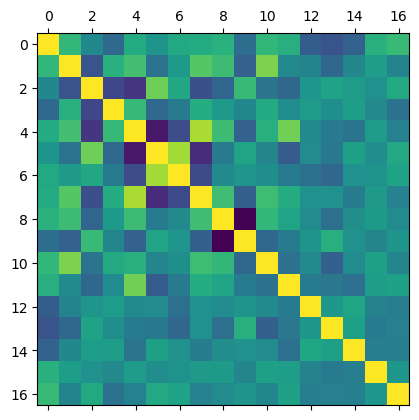

In [27]:
import matplotlib.pyplot as plt

plt.matshow(z_score_df.corr())
plt.show()

It seems like the most highly-correlated values are families with children and marriage, but using a threshold can help confirm which variables are most colinear:

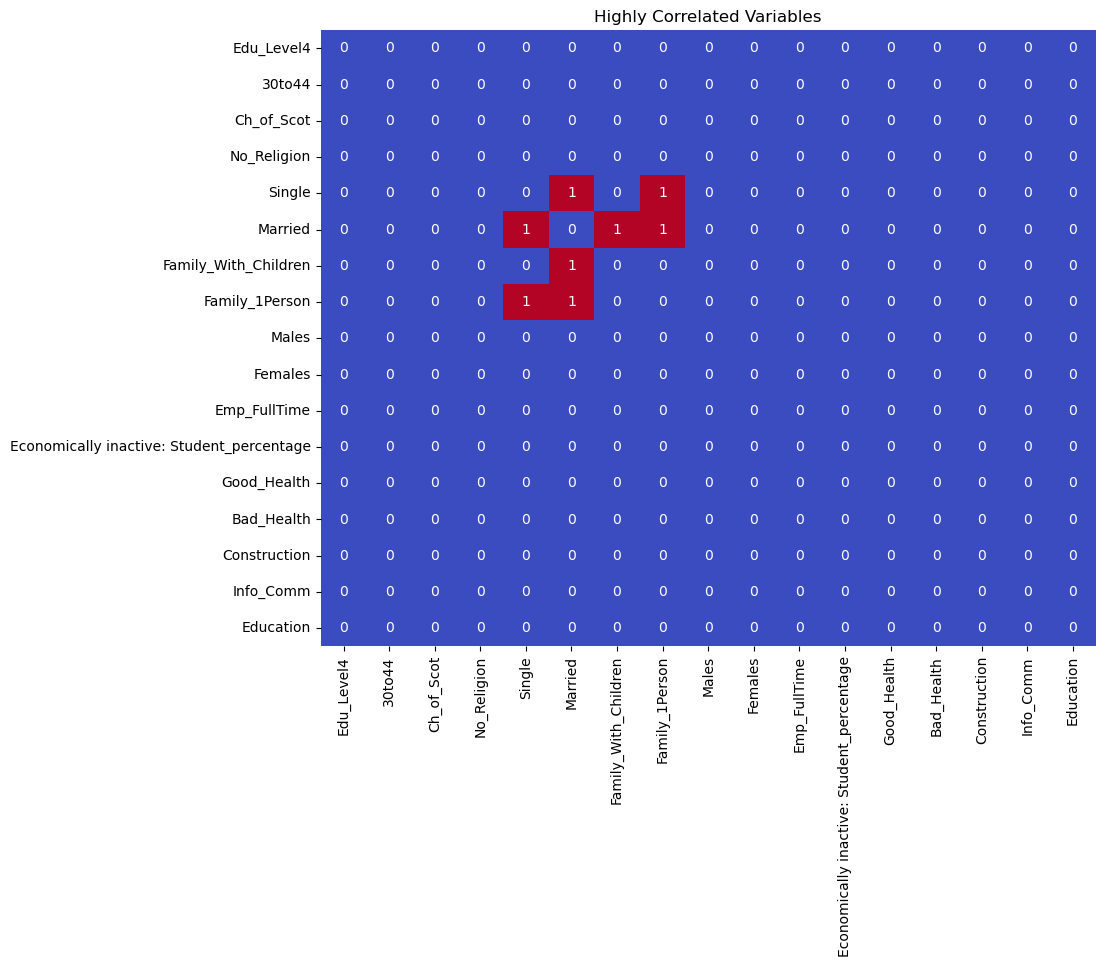

In [28]:
threshold = 0.70 # I've decided to use 0.70 after testing out a few values because it reveals relationships that make the most sense

highly_correlated = (corr.abs() > threshold) & (corr.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated, cmap='coolwarm', cbar=False, annot=True)

plt.title('Highly Correlated Variables')
plt.show()

# The plot will represent  BINARY table 0 for false( out of the threshold) and 1 for above the threshold.
# but I also coloured so it is easier to use and cute :) 

The most correlated variables are Single and 1-person household, and Married and Family with Children. I removed Married and Single because compared to Family with Children and 1-Person household, those two variables were more highly-correlated with other variables in the data frame as well, such as Ch_of_Scot and Economically inactive.

In [29]:
z_score_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1992 entries, 0 to 1991
Data columns (total 17 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Edu_Level4                                 1992 non-null   float64
 1   30to44                                     1992 non-null   float64
 2   Ch_of_Scot                                 1992 non-null   float64
 3   No_Religion                                1992 non-null   float64
 4   Single                                     1992 non-null   float64
 5   Married                                    1992 non-null   float64
 6   Family_With_Children                       1992 non-null   float64
 7   Family_1Person                             1992 non-null   float64
 8   Males                                      1992 non-null   float64
 9   Females                                    1992 non-null   float64
 10  Emp_FullTime            

In [30]:
z_score_df.drop(['Married', 'Single'], axis=1, inplace=True)
z_score_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1992 entries, 0 to 1991
Data columns (total 15 columns):
 #   Column                                     Non-Null Count  Dtype  
---  ------                                     --------------  -----  
 0   Edu_Level4                                 1992 non-null   float64
 1   30to44                                     1992 non-null   float64
 2   Ch_of_Scot                                 1992 non-null   float64
 3   No_Religion                                1992 non-null   float64
 4   Family_With_Children                       1992 non-null   float64
 5   Family_1Person                             1992 non-null   float64
 6   Males                                      1992 non-null   float64
 7   Females                                    1992 non-null   float64
 8   Emp_FullTime                               1992 non-null   float64
 9   Economically inactive: Student_percentage  1992 non-null   float64
 10  Good_Health             

In [31]:
# determining remailing co-linearities
corr_2 = z_score_df.corr()
corr_2.style.background_gradient(cmap='coolwarm')

,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education
Edu_Level4,1.000000,0.320338,-0.064975,-0.314581,0.211559,0.227784,0.274672,-0.274672,0.327393,0.253794,-0.406627,-0.481052,-0.368003,0.269019,0.351795
30to44,0.320338,1.000000,-0.478620,0.267500,0.079318,0.470398,0.374933,-0.374933,0.603292,-0.039526,-0.095483,-0.329663,-0.075647,0.113188,-0.094825
Ch_of_Scot,-0.064975,-0.478620,1.000000,-0.575921,0.190085,-0.509751,-0.343816,0.343816,-0.228935,-0.335929,0.047510,0.150070,0.101147,0.009728,0.214151
No_Religion,-0.314581,0.267500,-0.575921,1.000000,-0.173226,0.236396,0.080477,-0.080477,0.225819,-0.023964,0.100211,-0.007727,0.122907,-0.059931,-0.256459
Family_With_Children,0.211559,0.079318,0.190085,-0.173226,1.000000,-0.552326,-0.041587,0.041587,-0.002195,-0.178370,-0.258624,-0.343337,0.012793,0.015987,0.158353
Family_1Person,0.227784,0.470398,-0.509751,0.236396,-0.552326,1.000000,0.389805,-0.389805,0.380362,0.239895,0.014704,0.007969,-0.161803,0.080853,-0.110208
Males,0.274672,0.374933,-0.343816,0.080477,-0.041587,0.389805,1.000000,-1.000000,0.326360,0.165482,-0.035411,-0.264167,-0.013641,0.089046,-0.037434
Females,-0.274672,-0.374933,0.343816,-0.080477,0.041587,-0.389805,-1.000000,1.000000,-0.326360,-0.165482,0.035411,0.264167,0.013641,-0.089046,0.037434
Emp_FullTime,0.327393,0.603292,-0.228935,0.225819,-0.002195,0.380362,0.326360,-0.326360,1.000000,-0.244529,-0.045425,-0.387792,-0.035963,0.136673,-0.085566
Economically inactive: Student_percentage,0.253794,-0.039526,-0.335929,-0.023964,-0.178370,0.239895,0.165482,-0.165482,-0.244529,1.000000,-0.175768,-0.204003,-0.266202,0.114652,0.145357


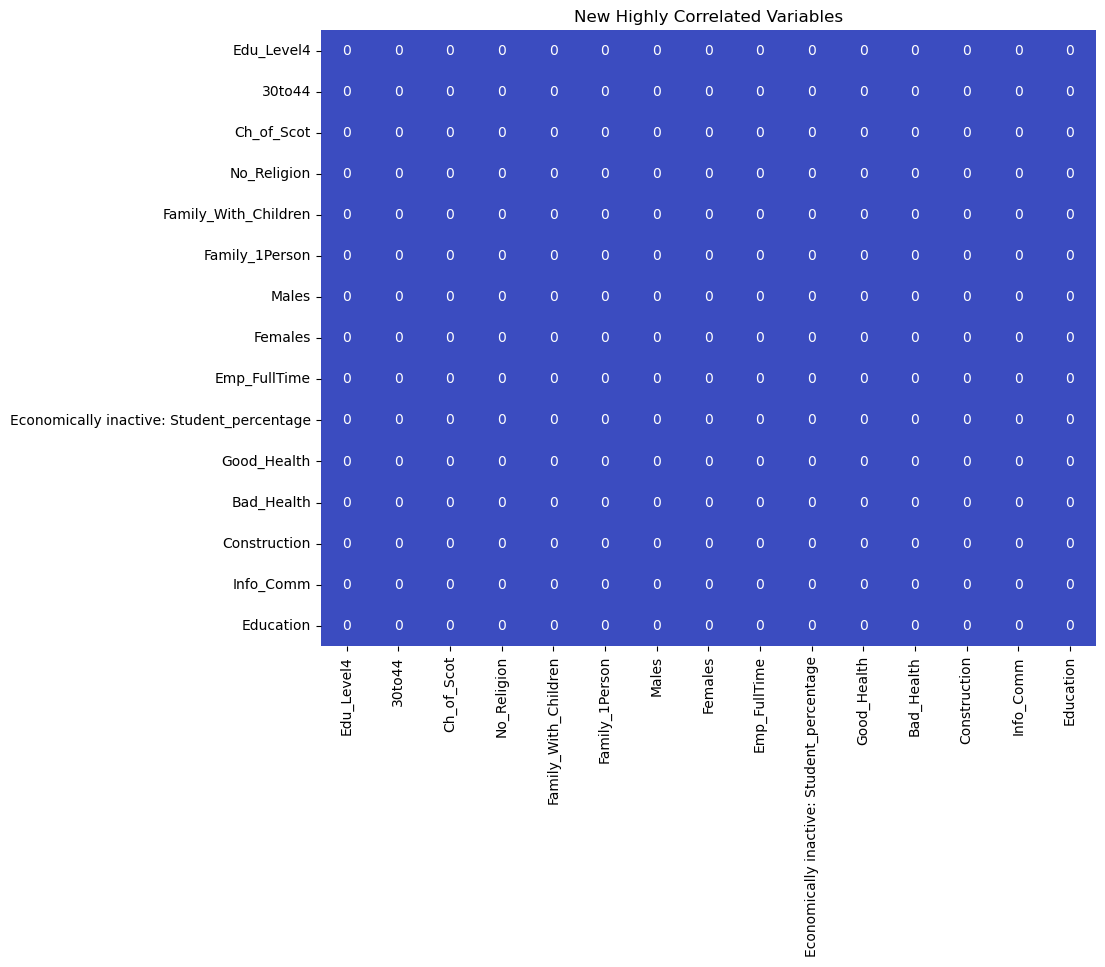

In [32]:
# seeing if there are anymore highly-correlated variables left
threshold = 0.7
highly_correlated_2 = (corr_2.abs() > threshold) & (corr_2.abs() < 1.0)

plt.figure(figsize=(10, 8))
sns.heatmap(highly_correlated_2, cmap='coolwarm', cbar=False, annot=True)

plt.title('New Highly Correlated Variables')
plt.show()

In [33]:
# checking for NaN values
contains_nan = z_score_df.isna().any().any()

if contains_nan:
    print("Oh no :( the DataFrame contains NaN values.")
else:
    print("Wahoo! the dataFrame does not contain NaN values. I'm the best")

Oh no :( the DataFrame contains NaN values.


In [34]:
# using imputation to fill in the NaN values using the means of the columns
z_score_df.fillna(z_score_df.mean(), inplace=True)

In [35]:
z_score_df.head()

,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education
0,-0.07,-0.28,0.70,-0.35,0.35,-0.67,-0.31,0.31,-0.19,-0.08,0.32,-0.70,0.16,-0.27,0.38
1,-1.15,-0.04,0.30,0.24,0.31,-0.35,-0.98,0.98,0.58,-0.86,-1.08,1.10,0.28,0.54,-0.17
2,1.77,-1.34,0.18,-1.60,1.56,-1.00,-0.65,0.65,-1.47,-0.09,-1.10,-0.15,-0.88,0.04,1.23
3,0.48,-0.17,-1.67,1.19,-0.95,0.44,1.55,-1.55,-0.30,2.03,-0.46,-0.96,-0.09,0.22,-0.47
4,-0.74,-0.09,-0.73,0.01,-0.94,1.05,1.45,-1.45,-1.98,0.89,1.50,0.86,-0.05,-0.98,-0.43


In [36]:
z_score_df.shape

(1992, 15)

## K-means clustering

In [37]:
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist, pdist

# KMeans with 10 clusters
kmeans = KMeans(n_clusters=10)
kmeans.fit(z_score_df)
labels = kmeans.predict(z_score_df)
cluster_centres = kmeans.cluster_centers_
z_score_df['Cluster'] = kmeans.labels_

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\threadpoolctl.py:1226: RuntimeWarning: 
Found Intel OpenMP ('libiomp') and LLVM OpenMP ('libomp') loaded at
the same time. Both libraries are known to be incompatible and this
can cause random crashes or deadlocks on Linux when loaded in the
same Python program.
Using threadpoolctl may cause crashes or deadlocks. For more
information and possible workarounds, please see
    https://github.com/joblib/threadpoolctl/blob/master/multiple_openmp.md

  warnings.warn(msg, RuntimeWarning)
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


In [38]:
z_score_df.head()

,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education,Cluster
0,-0.07,-0.28,0.70,-0.35,0.35,-0.67,-0.31,0.31,-0.19,-0.08,0.32,-0.70,0.16,-0.27,0.38,3
1,-1.15,-0.04,0.30,0.24,0.31,-0.35,-0.98,0.98,0.58,-0.86,-1.08,1.10,0.28,0.54,-0.17,6
2,1.77,-1.34,0.18,-1.60,1.56,-1.00,-0.65,0.65,-1.47,-0.09,-1.10,-0.15,-0.88,0.04,1.23,9
3,0.48,-0.17,-1.67,1.19,-0.95,0.44,1.55,-1.55,-0.30,2.03,-0.46,-0.96,-0.09,0.22,-0.47,8
4,-0.74,-0.09,-0.73,0.01,-0.94,1.05,1.45,-1.45,-1.98,0.89,1.50,0.86,-0.05,-0.98,-0.43,1


(array([288., 193., 224., 212., 225., 273., 171.,  35., 115., 256.]),
 array([0. , 0.9, 1.8, 2.7, 3.6, 4.5, 5.4, 6.3, 7.2, 8.1, 9. ]),
 <BarContainer object of 10 artists>)

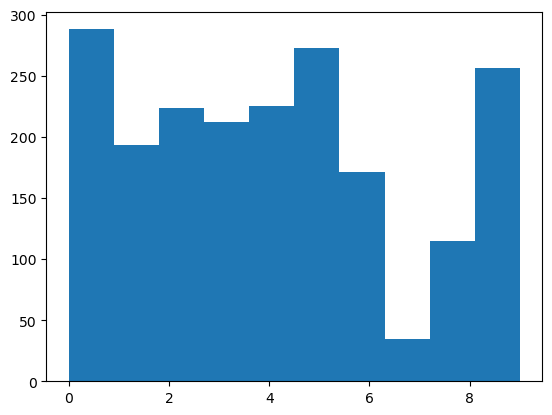

In [39]:
plt.hist(labels)

### Elbow method

There are relatively few data points in cluster 5, and most of them are contained in clusters 0-4 and 6, 7, and 9. Using the elbow method, this variation could be avoided by determining the ideal number of clusters for the data

Reminder of the ams of the cluster analysis:
* Each cluster should be homogeneous as possible
* Each cluster group should be distinct from the other groups
* The groups should be as evenly sized as possible

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is k

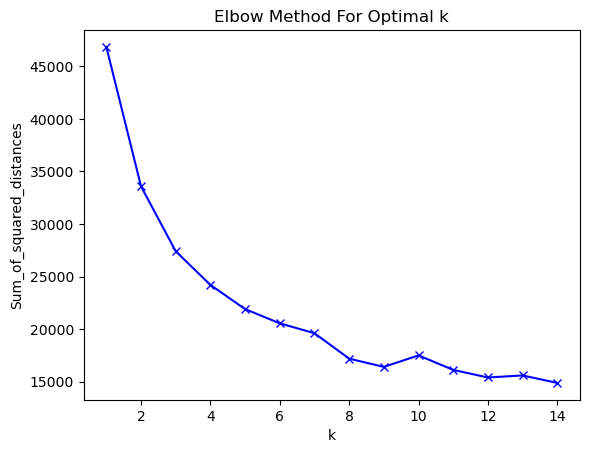

In [40]:
Sum_of_squared_distances = []

K_range = range(1,15)

for k in K_range:
 km = KMeans(n_clusters=k)
 km = km.fit(z_score_df)
 Sum_of_squared_distances.append(km.inertia_)
    
plt.plot(K_range, Sum_of_squared_distances, 'bx-')
plt.xlabel('k')
plt.ylabel('Sum_of_squared_distances')
plt.title('Elbow Method For Optimal k')
plt.show()

It seems like 4 or 5 could be optimal k values, so I will try out both, but first look at the between-cluster sum of squares to compare the difference between groups as k increases:

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(
C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is k

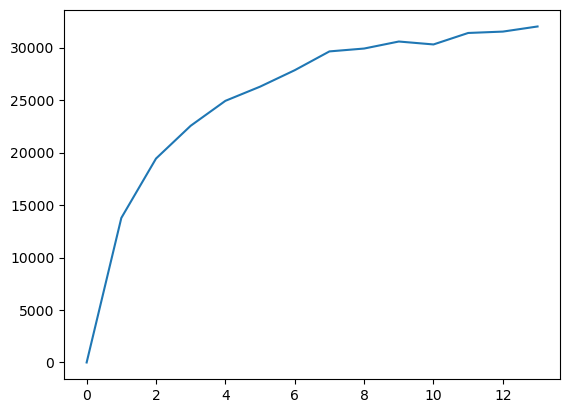

In [41]:
import numpy as np
def elbow(dataframe, n):
    kMeansVar = [KMeans(n_clusters=k).fit(dataframe.values) for k in range(1, n)] #making use of list comprehensions.
    centroids = [X.cluster_centers_ for X in kMeansVar]
    k_euclid = [cdist(dataframe.values, cent) for cent in centroids]
    dist = [np.min(ke, axis=1) for ke in k_euclid]
    wcss = [sum(d**2) for d in dist]
    tss = sum(pdist(dataframe.values)**2)/dataframe.values.shape[0]
    bss = tss - wcss
    plt.plot(bss)
    plt.show()
 
elbow(z_score_df,15)

In [42]:
# KMeans with 5 clusters, after the validation with the Elbow method.
k5means = KMeans(n_clusters=5)
k5means.fit(z_score_df)
labels = k5means.predict(z_score_df)
cluster5_centres = k5means.cluster_centers_

z_score_df['Cluster'] = k5means.labels_

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


In [43]:
z_score_df.head()

,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education,Cluster
0,-0.07,-0.28,0.70,-0.35,0.35,-0.67,-0.31,0.31,-0.19,-0.08,0.32,-0.70,0.16,-0.27,0.38,4
1,-1.15,-0.04,0.30,0.24,0.31,-0.35,-0.98,0.98,0.58,-0.86,-1.08,1.10,0.28,0.54,-0.17,2
2,1.77,-1.34,0.18,-1.60,1.56,-1.00,-0.65,0.65,-1.47,-0.09,-1.10,-0.15,-0.88,0.04,1.23,1
3,0.48,-0.17,-1.67,1.19,-0.95,0.44,1.55,-1.55,-0.30,2.03,-0.46,-0.96,-0.09,0.22,-0.47,1
4,-0.74,-0.09,-0.73,0.01,-0.94,1.05,1.45,-1.45,-1.98,0.89,1.50,0.86,-0.05,-0.98,-0.43,3


### Evaluating the classification with PCA

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


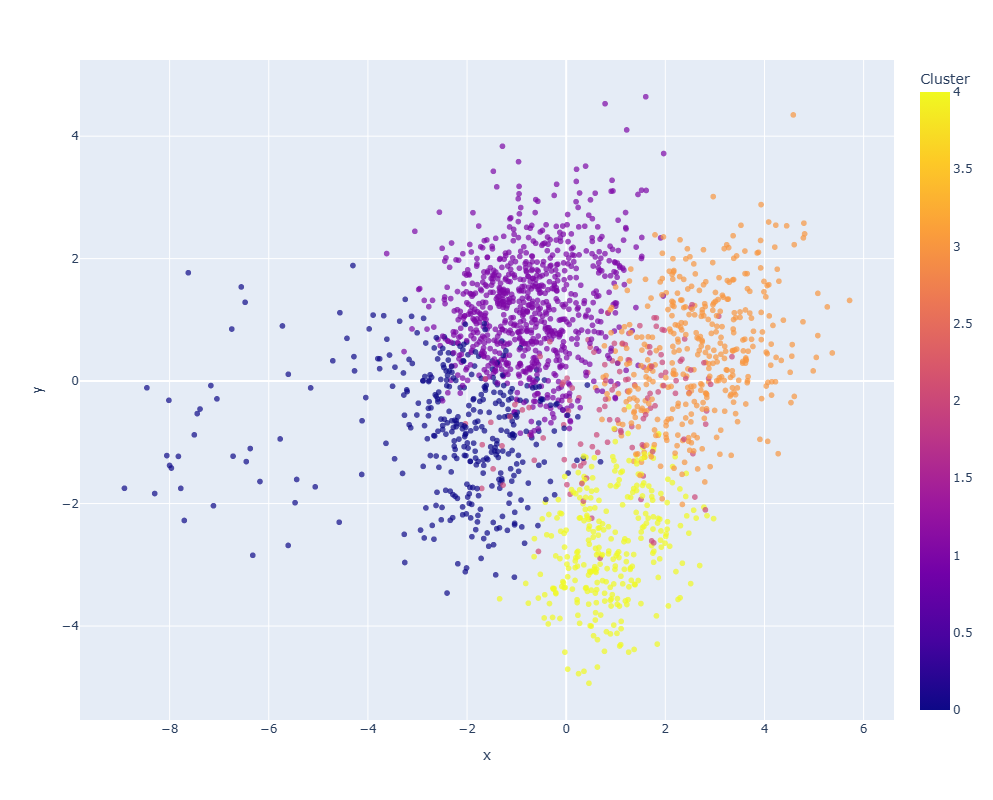

These two components explain 42.66% of the point variability.


<Figure size 1200x800 with 0 Axes>

In [44]:
# scatter plot based on 5 clusters
# Code based on the example provided here: 
# https://scikit-learn.org/stable/auto_examples/decomposition/plot_pca_iris.html#sphx-glr-auto-examples-decomposition-plot-pca-iris-py

import plotly.express as px
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

plt.figure(figsize=(12, 8))

kmeans = KMeans(n_clusters=5)
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA analysys.
pca = PCA(n_components=2).fit(stand_data_scaled) #PCA with 2 components, we can also use 3 components, but for now we will use 2 to make it easier to visualize the clusters.
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

# Create a scatter plot
fig = px.scatter(x=pca_result[:, 0], y=pca_result[:, 1], color=clusters,
                 labels={'color': 'Cluster'},
                 #title='Cluster Plot against 1st 2 Principal Components',
                 opacity=0.7,
                 width=800, 
                 height=800)

plt.tight_layout()
fig.show()

print(f"These two components explain {(variance_ratio.sum()*100):.2f}% of the point variability.")


#### Four different values for k, I chose k = 5

k = 4: distinct clusters but might be over-simplifying them
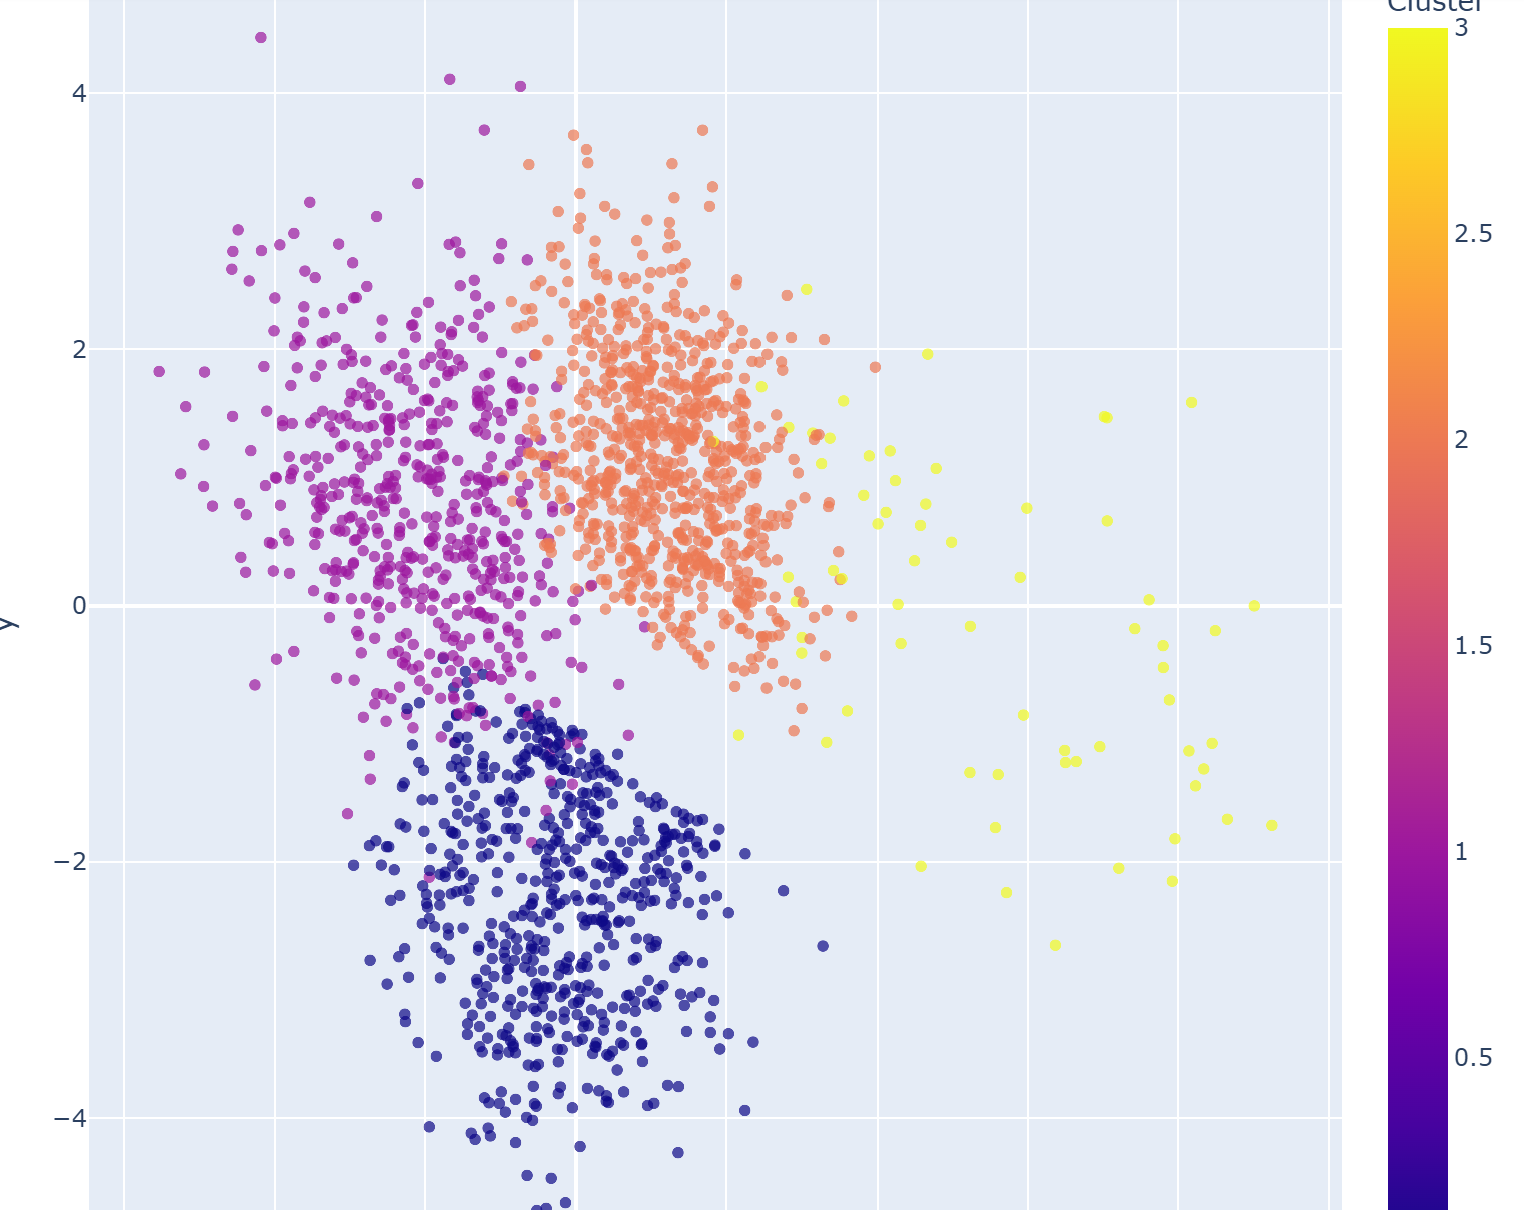

k = 5: there is some overlap among clusters but generally appropriate
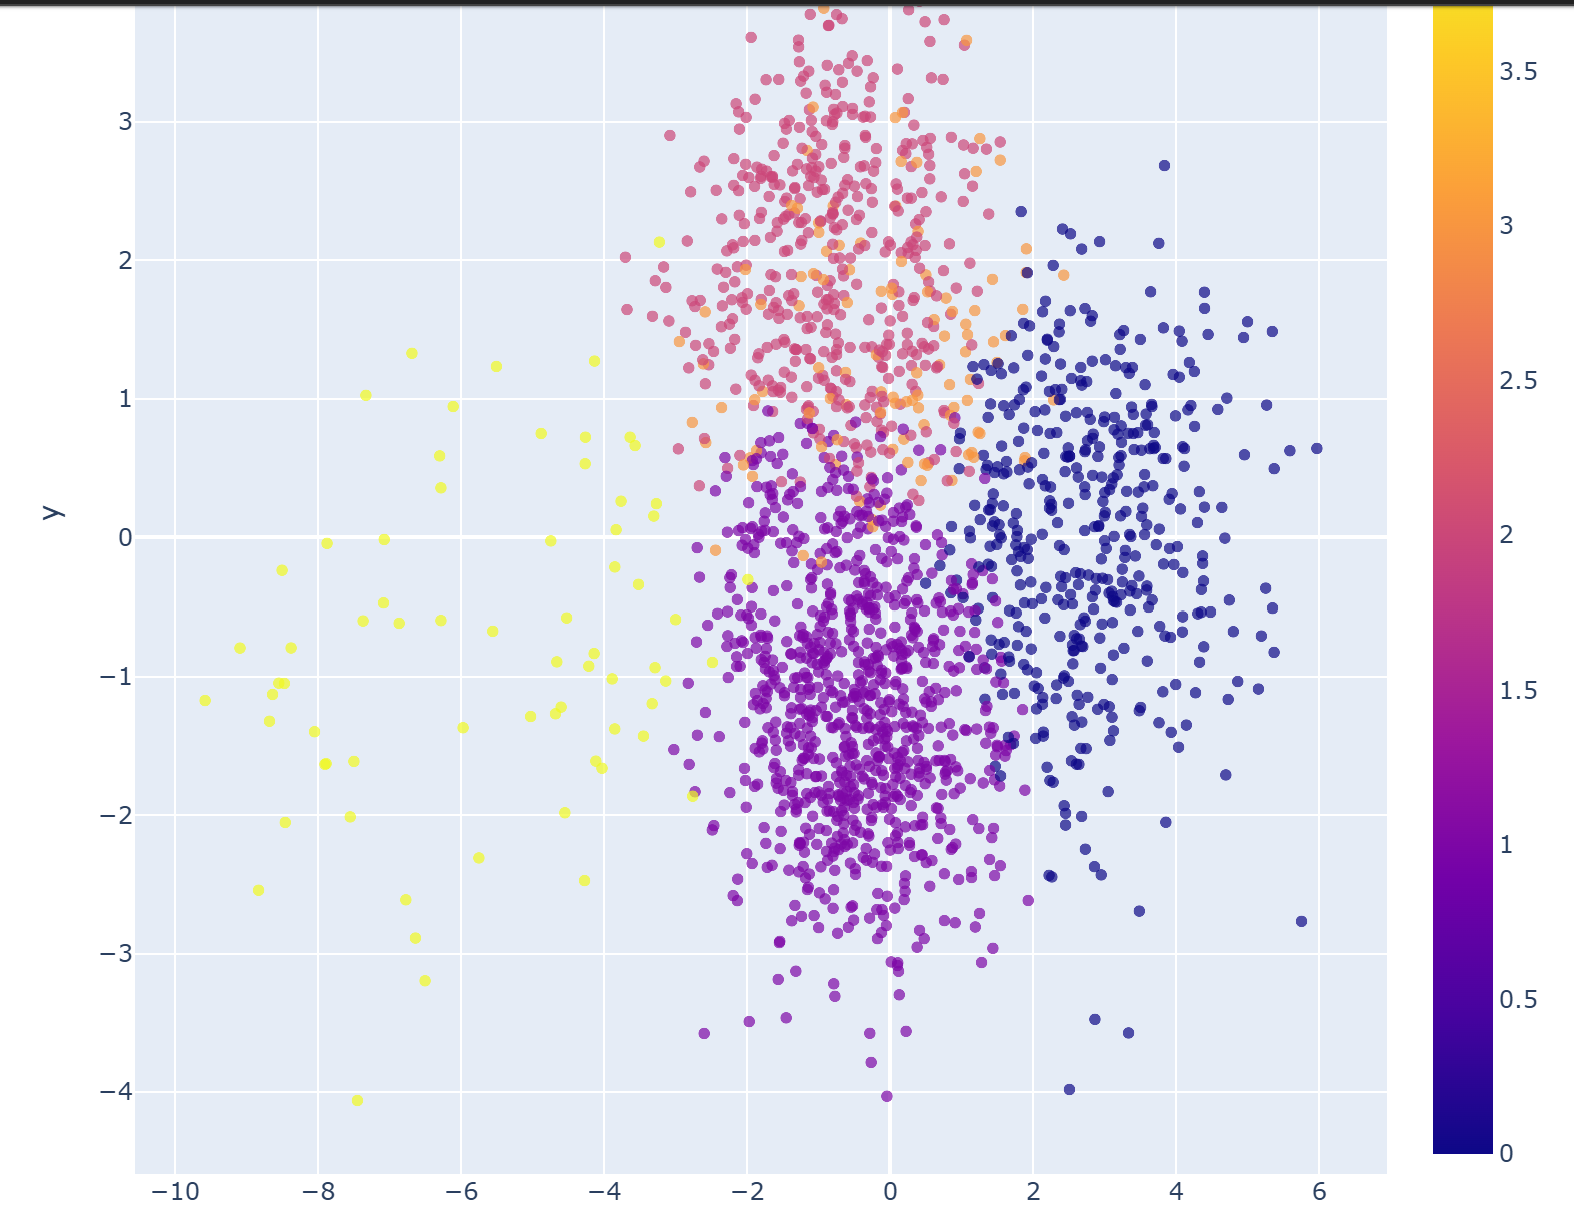

k = 6: clusters are not as homogeneous as when k = 5
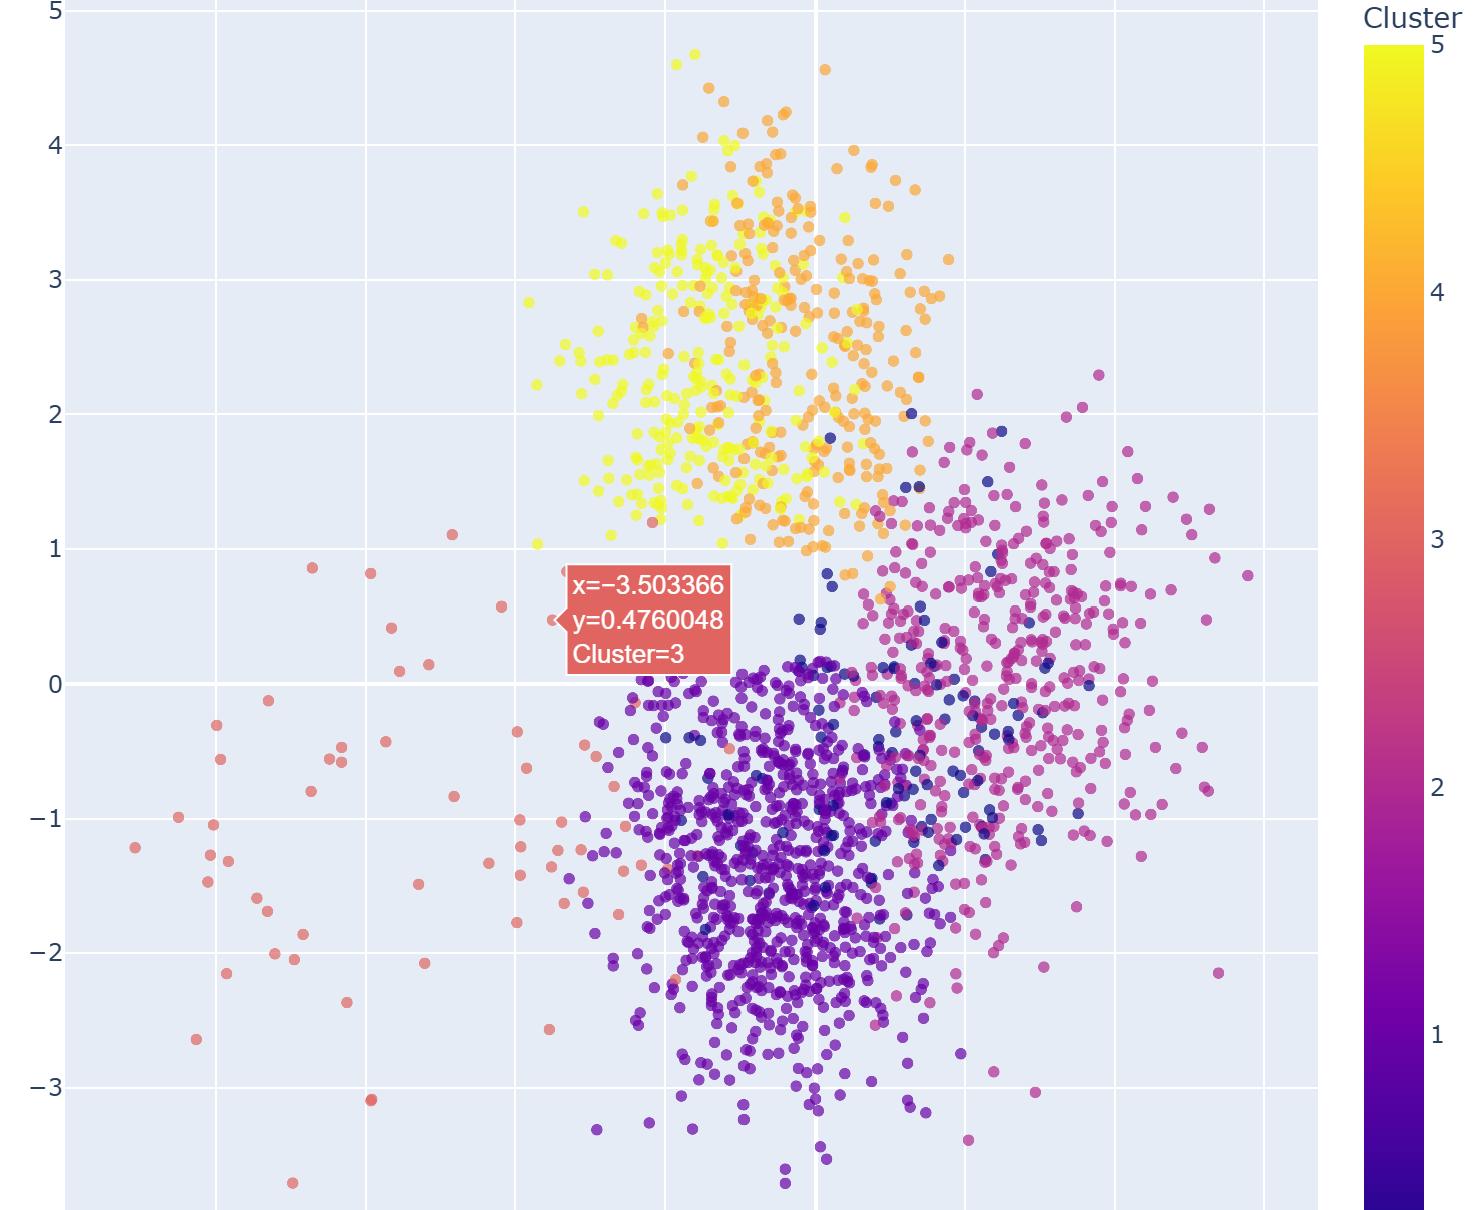

k = 7: too many clusters
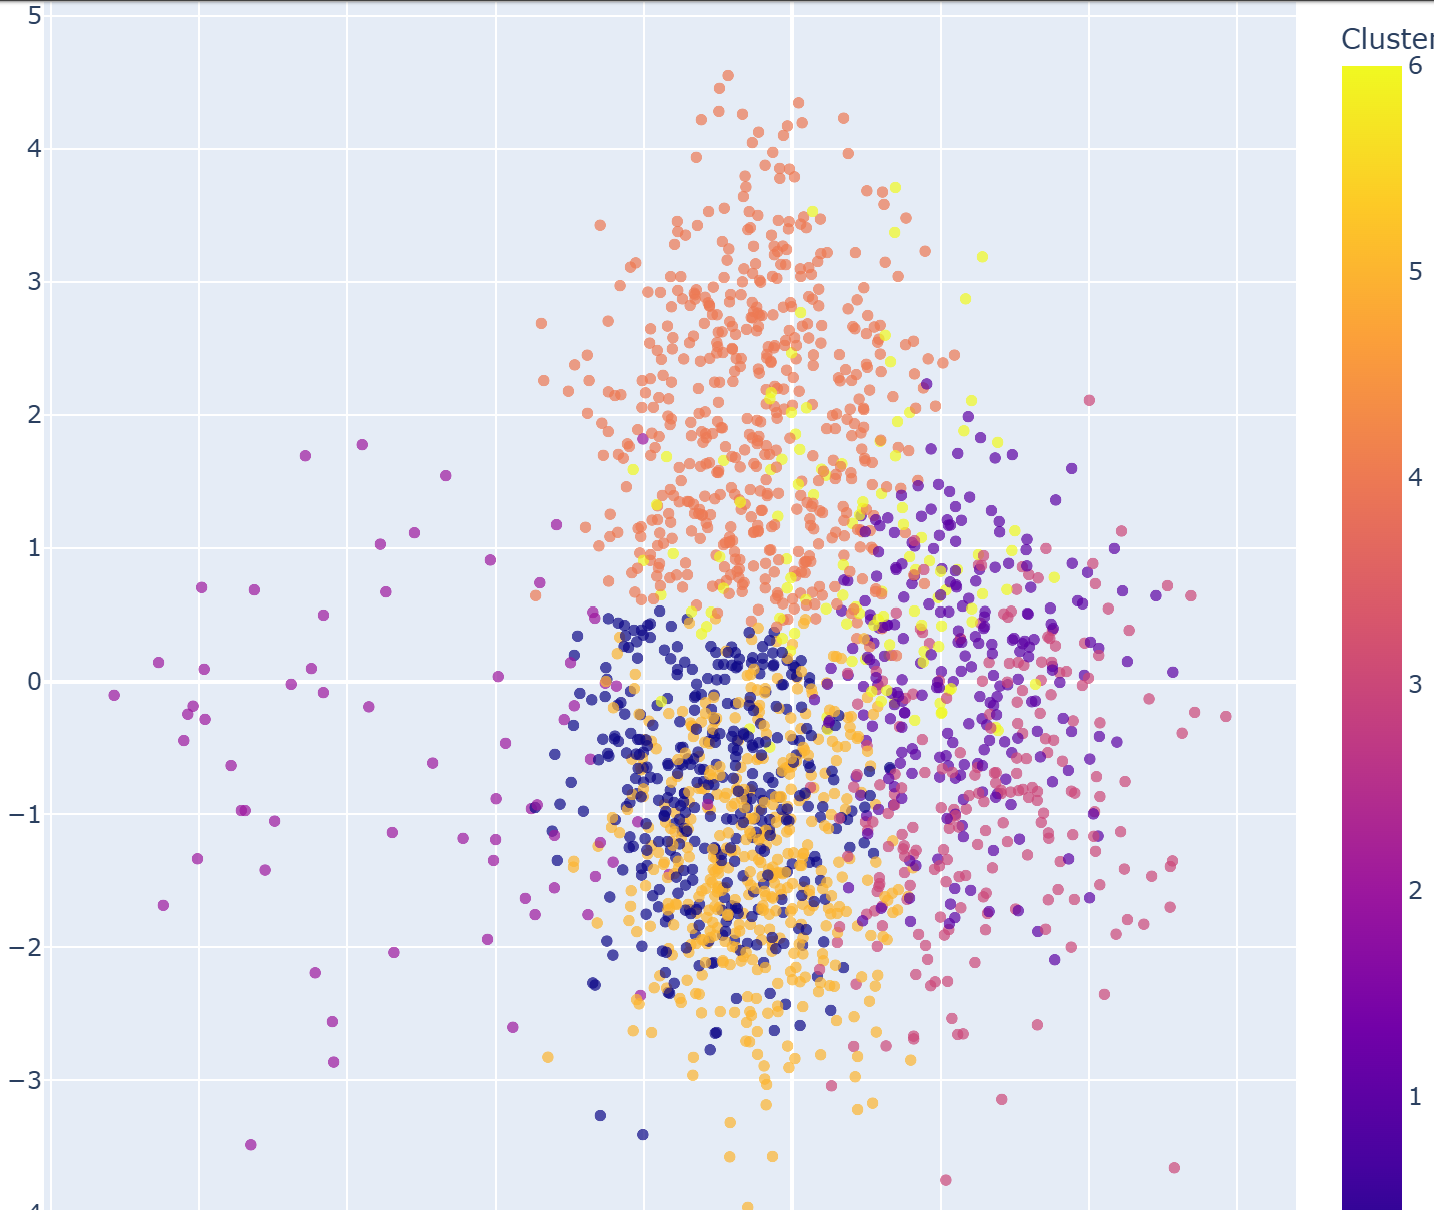

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


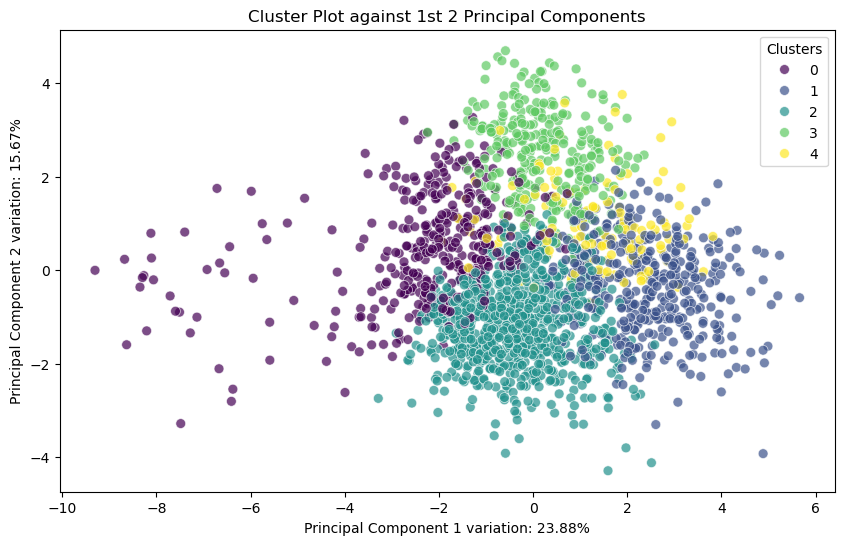

In [45]:
# Here is a static figure with the point variability included in the x/y-axis label.
# So we can see what variability is provided by each component.

kmeans = KMeans(n_clusters=5)
clusters = kmeans.fit_predict(z_score_df)

z_score_df['Cluster'] = clusters

# Standardize the data for PCA
scaler = StandardScaler()
stand_data_scaled = scaler.fit_transform(z_score_df)

# PCA
pca = PCA(n_components=2).fit(stand_data_scaled)
pca_result = pca.transform(stand_data_scaled)

#Percentage of variance explained by each of the selected components.
variance_ratio = pca.explained_variance_ratio_

plt.figure(figsize=(10, 6))
sns.scatterplot(x=pca_result[:, 0], y=pca_result[:, 1], hue=clusters, palette='viridis', s=50, alpha=0.7)
plt.title('Cluster Plot against 1st 2 Principal Components')
plt.xlabel(f'Principal Component 1 variation: {variance_ratio[0]*100:.2f}%')
plt.ylabel(f'Principal Component 2 variation: {variance_ratio[1]*100:.2f}%')
plt.legend(title='Clusters')
plt.show()


In [46]:
# KMeans clustering
kmeans = KMeans(n_clusters=5)
clusters = kmeans.fit_predict(z_score_df)

# Get the cluster centers
cluster_centers = kmeans.cluster_centers_


# Get the cluster centers
cluster_centers = pd.DataFrame(kmeans.cluster_centers_, columns=z_score_df.columns)

# Create a new DataFrame with cluster assignments and column names
#result_df = pd.DataFrame({'Cluster': clusters, 'Column': z_score_df.columns})

cluster_centers.head(6)

C:\Users\silog\miniforge3\envs\ua\lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=8.
  warnings.warn(


,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Family_With_Children,Family_1Person,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education,Cluster
0,0.86,-0.08,0.05,-0.41,0.89,-0.37,-5.12e-03,5.12e-03,-0.31,0.76,-0.83,-0.55,-0.49,0.24,0.62,3.28e+00
1,0.89,0.97,-0.68,0.16,-0.64,1.27,8.21e-01,-8.21e-01,1.07,0.23,-0.24,-0.39,-0.43,0.36,-0.11,1.03e+00
2,-0.27,-0.95,1.35,-0.97,-0.13,-0.69,-6.86e-01,6.86e-01,-0.57,-0.41,0.35,0.42,0.10,0.06,0.40,-1.33e-15
3,-0.62,0.11,-0.23,0.26,0.01,0.03,4.94e-01,-4.94e-01,-0.03,-0.29,0.56,0.19,0.71,-0.32,-0.37,1.99e+00
4,-0.95,-0.11,-0.40,0.92,-0.17,-0.26,-6.30e-01,6.30e-01,-0.19,-0.37,0.27,0.39,0.19,-0.36,-0.54,1.99e+00


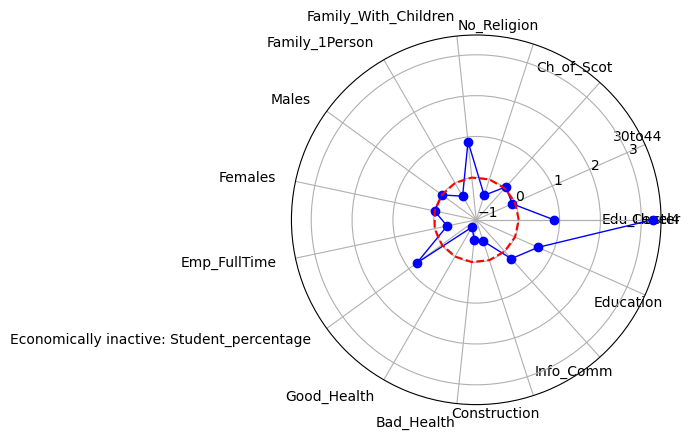

In [47]:
# Code adapted from:
# https://matplotlib.org/stable/gallery/pie_and_polar_charts/polar_demo.html

first_row_centers = cluster_centers.iloc[0, :]

# len of features
num_features = len(first_row_centers)

# polar coordinates
theta = np.linspace(0, 2 * np.pi, num_features, endpoint=True)

fig, ax = plt.subplots(subplot_kw={'projection': 'polar'})
ax.plot(theta, first_row_centers, linewidth=1, color='blue', marker='o', label='Centers')
# Add an extra red line at the 0.0 value
ax.plot(theta, np.zeros_like(first_row_centers), color='red', linestyle='--', label='Avarage')

ax.set_xticks(theta)
ax.set_xticklabels(cluster_centers.columns, rotation=45, ha='right')

plt.show()
#Ignore the cluster polar values, and focus in he census variables.

Interpretations
Cluster 0 is the most densely grouped, and cluster 1 is the most sparsely grouped. Cluster 4 shows some overlap with clusters 2 and 3. The radial plot is very useful in revealing which variables are part of which cluster, and here are some tentative labels for groups based on this plot (for some reason the numbering of clusters is incorrect but the points can still be put into 5 groups):
Group 0: Christian families with parents working in construction
Group 1: 30-44 year olds who work in info communications
Group 2: Single-person households of people working in education or info communications
Group 3: Educated non-religious men and women
Group 4: Full-time students

## Mapping the clusters

In [48]:
list(z_score_df.columns)

['Edu_Level4',
 '30to44',
 'Ch_of_Scot',
 'No_Religion',
 'Family_With_Children',
 'Family_1Person',
 'Males',
 'Females',
 'Emp_FullTime',
 'Economically inactive: Student_percentage',
 'Good_Health',
 'Bad_Health',
 'Construction',
 'Info_Comm',
 'Education',
 'Cluster']

In [49]:
# removing the standardised percentages
z_score_df.drop([
 'Edu_Level4',
 '30to44',
 'Ch_of_Scot',
 'No_Religion',
 'Family_1Person',
 'Males',
 'Females',
 'Emp_FullTime',
 'Economically inactive: Student_percentage',
 'Good_Health',
 'Bad_Health',
 'Construction',
 'Info_Comm',
 'Education'], axis=1, inplace=True)
z_score_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1992 entries, 0 to 1991
Data columns (total 2 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Family_With_Children  1992 non-null   float64
 1   Cluster               1992 non-null   int32  
dtypes: float64(1), int32(1)
memory usage: 23.5 KB


In [50]:
# Concatenate the resulting tables.
final_df = pd.concat([aberdeen_census_data, z_score_df], axis=1, ignore_index=False)
final_df = final_df.loc[:,~final_df.columns.duplicated()].copy()  # remove duplicate Family_With_Children table
final_df.head()

,code,Popcount,HHcount,DataZone,geometry,Edu_Level4,30to44,Ch_of_Scot,No_Religion,Single,...,Males,Females,Emp_FullTime,Economically inactive: Student_percentage,Good_Health,Bad_Health,Construction,Info_Comm,Education,Cluster
0,S00089001,115,55,S01006594,"POLYGON ((393393.000 805102.000, 393384.000 80...",32.04,19.13,33.91,44.35,32.04,...,47.83,52.17,43.96,5.49,33.91,0.87,6.78,1.69,10.17,0
1,S00090016,100,50,S01006720,"POLYGON ((389796.000 808485.001, 389817.000 80...",12.79,21.00,29.00,51.00,23.26,...,44.00,56.00,53.33,0.00,24.00,7.00,7.27,3.64,7.27,2
2,S00089741,109,45,S01006572,"POLYGON ((391410.771 806073.119, 391383.319 80...",64.77,11.01,27.52,30.28,12.50,...,45.87,54.13,28.38,5.41,23.85,2.75,2.44,2.44,14.63,3
3,S00088978,60,33,S01006585,"POLYGON ((393596.593 806042.095, 393651.000 80...",41.82,20.00,5.00,61.67,70.91,...,58.33,41.67,42.59,20.37,28.33,0.00,5.71,2.86,5.71,4
4,S00090442,97,64,S01006667,"POLYGON ((394659.000 808248.000, 394611.964 80...",20.00,20.62,16.49,48.45,54.44,...,57.73,42.27,22.22,12.35,42.27,6.19,5.88,0.00,5.88,2


In [51]:
final_df.columns

Index(['code', 'Popcount', 'HHcount', 'DataZone', 'geometry', 'Edu_Level4',
       '30to44', 'Ch_of_Scot', 'No_Religion', 'Single', 'Married',
       'Family_With_Children', 'Family_1Person', 'Males', 'Females',
       'Emp_FullTime', 'Economically inactive: Student_percentage',
       'Good_Health', 'Bad_Health', 'Construction', 'Info_Comm', 'Education',
       'Cluster'],
      dtype='object')

In [52]:
def rename_column(x): 
    x = x.replace("0", "Christian families with parents working in construction")
    x = x.replace("1", "30-44 year olds who work in info communications")
    x = x.replace("2", " Educated non-religious men and women")
    x = x.replace("3", "Full-time students")
    x = x.replace("4", "Single-person households of people working in education or info communications")
    # Add more values as you need. As many as clusters you have
    return x

final_df['Cluster'] = final_df['Cluster'].apply(rename_column)

AttributeError: 'int' object has no attribute 'replace'

In [53]:
final_df.explore(column='Cluster', cmap='Set1', tiles='Open Street Map')

# Naming the clusters

Last part of this process is formulating names for geodemographic groups, unfortunately is not easy and can be contentious. Essentially, the names are derivative of the researcher’s perceptions of the cluster centres and sometimes also consider their geographic distributions. 

> Names should be informative, short and memorable. They should also not make unnecessary assumptions or be derogatory in any way. Look at all of your plots - can you derive names for your clusters?

It is not uncommon for one of your cluster groups to represent the typical traits of the entire dataset. This  group would, therefore, have very moderate **Z-scores**. Once you are happy with your clusters making sense, being nameable and looking sensible across all of your plots you are finished.

As a final step, try renaming your final clusters and then mapping the results. Here you have an example of how to rename your clusters using a `function` and `replace` methods.

````python

def rename_column(x): 
    x = x.replace("1", "Your Name")
    x = x.replace("2", "Your Second Name")
    # Add more values as you need. As many as clusters you have
    return x

df['Cluster'] = df['Cluster'].apply(rename_column)

````
For example, the names and pen portraits for the supergroups, groups, and subgroups of the 2011 Output Area Classification can be downloaded from this [link](https://webarchive.nationalarchives.gov.uk/ukgwa/20160105160709/http://www.ons.gov.uk/ons/guide-method/geography/products/area-classifications/ns-area-classifications/ns-2011-area-classifications/pen-portraits-and-radial-plots/pen-portraits-oa.pdf).